# MCWF moment-saving pipeline

Run the custom MCWF solver, retain trajectory-resolved first and symmetric second SU(3) generator moments, form their ensemble mean, compute generic J and S moments, and compute generalized squeezing from the stored moments.

The notebook constructs the dressed frame explicitly before squeezing. Lab-frame and dressed-frame moment series remain separate, making the basis required by each analysis visible.

In [1]:
from pathlib import Path
import sys

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from common.plotting import (
    plot_bloch_angles,
    plot_spin_components,
    plot_squeezing,
)
from common.utils.parameters import (
    mcwf_dt_from_scales,
    omega_c,
    scaled_N_Gamma,
)
from common.utils.phases import default_three_phase_protocol
from parser.mcwf import MCWFSolverParameters
from parser.moments import MomentSeries, SimulationMetadata
from post_analysis import (
    build_dressed_basis_transformation,
    compute_gell_mann_rotation,
    compute_j_moments,
    compute_mean_generator_moments,
    compute_s_moments,
    compute_squeezing,
    rotate_generator_moments,
)
from solvers.mcwf.ensamble_sim import run_trajectory_ensemble

%reload_ext autoreload
%autoreload 2

/Users/ashar/.pyenv/versions/cavity-OAT_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Parameters

These defaults follow the single-group conventions and parameter values in `main.ipynb`. Reduce `ntraj`, `Ni`, `dN`, or `num_snapshots` for a quick local smoke run.

In [2]:
# Shared physical and saved-time parameters
Gamma = 1.0
num_snapshots = 500

# MCWF ensemble parameters
Ni = [10,10]
omega_i = [0.7]
joint_probability = 0.4
ntraj = 100
seed = 1234
n_processes = -1

# N*Gamma-scaled model parameters
N_total = sum(Ni)
Omega_factor = 0.15
delta_factor = 0.02
Omega0 = scaled_N_Gamma(Omega_factor, N_total, Gamma)
delta0 = scaled_N_Gamma(delta_factor, N_total, Gamma)
dt = mcwf_dt_from_scales(Omega0, delta0, N_total, Gamma)

phase_protocol = default_three_phase_protocol(
    durations=(10.0, 10.0, 10.0),
    delta0=delta0,
    Omega0=Omega0,
)
simulation_metadata = SimulationMetadata(
    Ni=tuple(Ni),
    omega_i=tuple(omega_i),
    Gamma=Gamma,
    phase_protocol=phase_protocol,
)

Omega_c = omega_c(N_total // 2, Gamma)
print(f"Omega0 = {Omega0}")
print(f"Omega/Omega_c ratio = {Omega0 / Omega_c}")
print(f"delta0 = {delta0}")
print(f"dt = {dt}")

Omega0 = 3.0
Omega/Omega_c ratio = 0.6
delta0 = 0.4
dt = 0.0033333333333333335


## MCWF simulation

`run_trajectory_ensemble` returns the trajectory-resolved first and symmetric second generator moments directly. Complete trajectories remain identifiable along axis zero.

In [3]:
mcwf_moments = MomentSeries(
    num_snapshots=num_snapshots,
    metadata=simulation_metadata,
)
mcwf_parameters = MCWFSolverParameters(
    Ni=simulation_metadata.Ni,
    omega_i=simulation_metadata.omega_groups,
    Gamma=simulation_metadata.Gamma,
    phase_protocol=simulation_metadata.phase_protocol,
    joint_probability=joint_probability,
    sector_distribution="binomial",
    dt=dt,
    shifted_jump_operator=True,
)
mcwf_ensemble = run_trajectory_ensemble(
    mcwf_parameters,
    t_eval=mcwf_moments.t,
    seed=seed,
    ntraj=ntraj,
    n_processes=n_processes,
)

# Retain the full trajectory axis in the analysis container.
mcwf_moments.generator_moments = mcwf_ensemble.moments

Initial sector construction: 121 sectors.

Filter                       Sectors left   Sector % input   Sector % initial   Probability % input   Probability % initial
---------------------------------------------------------------------------------------------------------------------------
dN filter                              11            9.09%              9.09%                17.62%                  17.62%
Joint-probability filter               11          100.00%              9.09%               100.00%                  17.62%


simulate trajectories: 100%|██████████| 100/100 [00:46<00:00,  2.15it/s]

Simulation step summary (avg per trajectory): total steps=9509.36, steps without precompute=527.36


## Mean generator moments

Average complete trajectories only in post-analysis. The returned mean keeps a singleton trajectory axis so it can use the same moment-series class.

In [4]:
mcwf_moments.mean_generator_moments = compute_mean_generator_moments(
    mcwf_moments.generator_moments,
)

## Generic J and S moments

Both analyses consume the averaged lab-frame generator moments. The simulator-specific wavefunction extractors are not used.

In [5]:
mcwf_moments.J = compute_j_moments(
    mcwf_moments.mean_generator_moments,
    metadata=mcwf_moments.metadata,
)
mcwf_moments.S = compute_s_moments(
    mcwf_moments.mean_generator_moments,
    mcwf_moments.J,
)

## Dressed generator moments

Construct the shared dressed basis and its Gell--Mann adjoint rotation from the ensemble-level J and S angles. Apply that same frame to the mean and to every complete trajectory. `U` and `R` remain transient derived arrays rather than fields of `MomentSeries`.

In [6]:
U = build_dressed_basis_transformation(mcwf_moments.J, mcwf_moments.S)
R = compute_gell_mann_rotation(U)

mean_dressed_generator_moments = rotate_generator_moments(
    mcwf_moments.mean_generator_moments,
    R,
)
dressed_trajectory_generator_moments = rotate_generator_moments(
    mcwf_moments.generator_moments,
    R,
)

## Generalized squeezing

The squeezing calculation consumes the averaged dressed moments, constructs one $4\times4$ covariance per group, and optionally constructs the full-system covariance by summing every group-pair block.

In [7]:
mcwf_moments.squeezing = compute_squeezing(
    mean_dressed_generator_moments,
    mcwf_moments.J,
    metadata=mcwf_moments.metadata,
    include_full_system=False,
)

## J angles

Text(0.5, 0, '$\\Gamma t$')

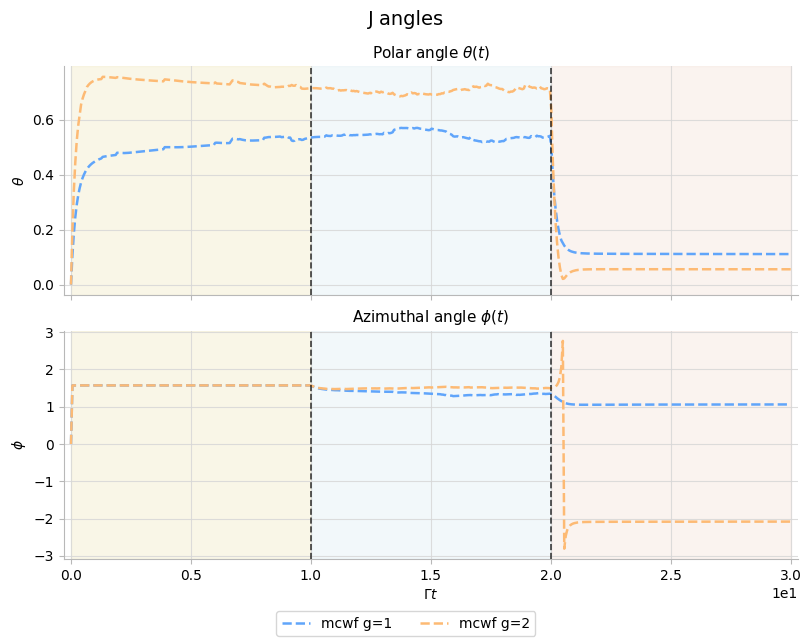

In [8]:
j_angle_fig, j_angle_axes = plot_bloch_angles(
    mcwf_moments.J.t,
    mcwf_moments.J.theta,
    mcwf_moments.J.phi,
    labels=[
        f"mcwf g={group_index + 1}"
        for group_index in range(len(mcwf_moments.J.x))
    ],
    phase_protocol=mcwf_moments.metadata.phase_protocol,
    colour_family_index=None,
    shade_index=1,
    linestyle="--",
    title="J angles",
)
j_angle_fig.supxlabel("")
j_angle_axes[-1].set_xlabel(r"$\Gamma t$")


## J moments

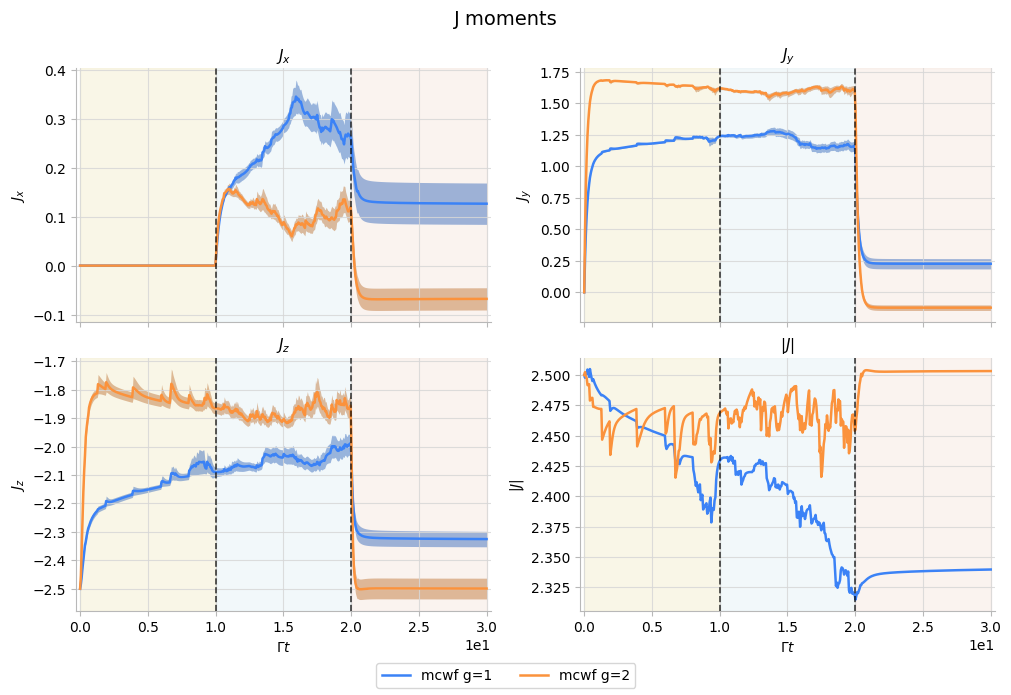

In [9]:
j_moment_fig, j_moment_axes = plot_spin_components(
    mcwf_moments.J.t,
    mcwf_moments.J.x,
    mcwf_moments.J.y,
    mcwf_moments.J.z,
    mcwf_moments.J.length,
    x_sem=mcwf_moments.J.x_sem,
    y_sem=mcwf_moments.J.y_sem,
    z_sem=mcwf_moments.J.z_sem,
    labels=[
        f"mcwf g={group_index + 1}"
        for group_index in range(len(mcwf_moments.J.x))
    ],
    phase_protocol=mcwf_moments.metadata.phase_protocol,
    colour_family_index=None,
    shade_index=2,
    linestyle="-",
    title="J moments",
)
j_moment_fig.supxlabel("")
for ax in j_moment_axes[2:]:
    ax.set_xlabel(r"$\Gamma t$")


## Squeezing plots

Plot the group-resolved squeezing series together, then plot the optional full-system result separately.

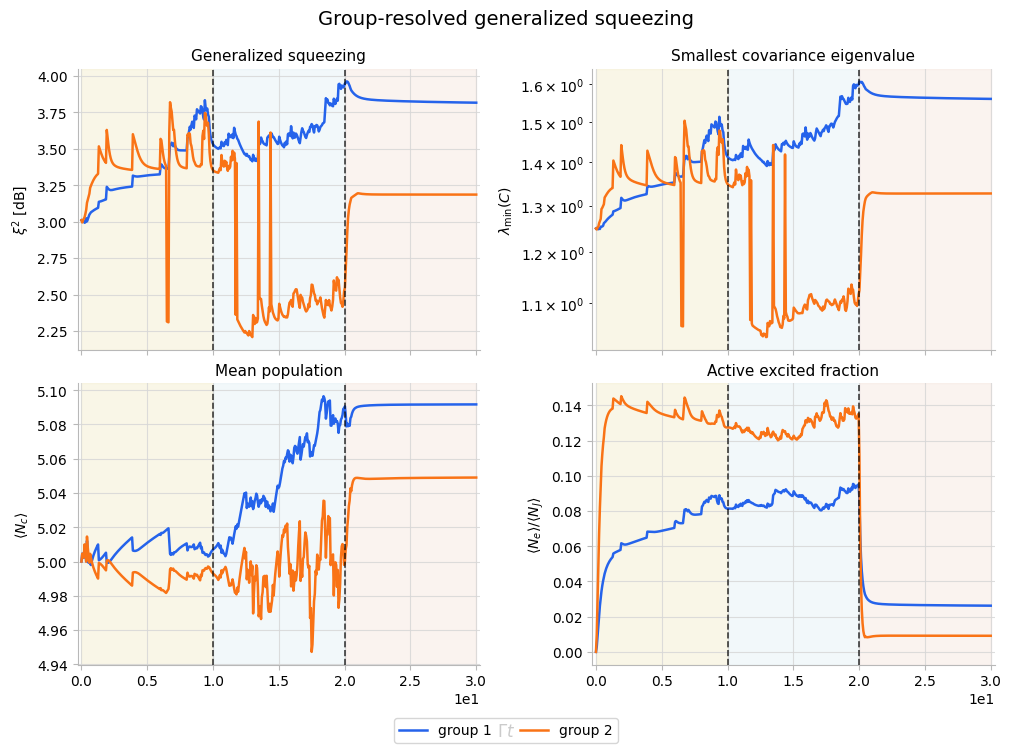

In [10]:
group_squeezing = mcwf_moments.squeezing.group_resolved
group_squeezing_fig, group_squeezing_axes = plot_squeezing(
    group_squeezing[0].t,
    tuple(series.xi2 for series in group_squeezing),
    tuple(series.lambda_min for series in group_squeezing),
    tuple(series.N_c for series in group_squeezing),
    tuple(
        series.excited_fraction_active for series in group_squeezing
    ),
    labels=[
        f"group {group_index + 1}"
        for group_index in range(len(group_squeezing))
    ],
    phase_protocol=mcwf_moments.metadata.phase_protocol,
    title="Group-resolved generalized squeezing",
)

In [11]:
# full_system_squeezing = mcwf_moments.squeezing.full_system
# if full_system_squeezing is None:
#     raise RuntimeError(
#         "Set include_full_system=True before computing squeezing."
#     )
# full_system_squeezing_fig, full_system_squeezing_axes = plot_squeezing(
#     full_system_squeezing.t,
#     full_system_squeezing.xi2,
#     full_system_squeezing.lambda_min,
#     full_system_squeezing.N_c,
#     full_system_squeezing.excited_fraction_active,
#     labels=["full system"],
#     phase_protocol=mcwf_moments.metadata.phase_protocol,
#     title="Full-system generalized squeezing",
# )

## Output summary and consistency check

In [12]:
# Rotation is linear and uses one shared ensemble frame, so rotating and
# averaging must commute.
mean_of_dressed_trajectories = compute_mean_generator_moments(
    dressed_trajectory_generator_moments,
)
assert (
    abs(
        mean_of_dressed_trajectories.first_moments
        - mean_dressed_generator_moments.first_moments
    ).max()
    < 1e-10
)
assert (
    abs(
        mean_of_dressed_trajectories.second_moments
        - mean_dressed_generator_moments.second_moments
    ).max()
    < 1e-10
)

{
    "lab first moments (R, T, G, 8)": (
        mcwf_moments.generator_moments.first_moments.shape
    ),
    "lab packed second moments (R, T, K)": (
        mcwf_moments.generator_moments.second_moments.shape
    ),
    "mean first moments": (
        mcwf_moments.mean_generator_moments.first_moments.shape
    ),
    "U (T, G, 3, 3)": U.shape,
    "R (T, G, 8, 8)": R.shape,
    "dressed first moments": (
        dressed_trajectory_generator_moments.first_moments.shape
    ),
    "dressed packed second moments": (
        dressed_trajectory_generator_moments.second_moments.shape
    ),
    "group squeezing results": len(
        mcwf_moments.squeezing.group_resolved
    ),
    "full-system squeezing computed": (
        mcwf_moments.squeezing.full_system is not None
    ),
}

{'lab first moments (R, T, G, 8)': (100, 500, 2, 8),
 'lab packed second moments (R, T, K)': (100, 500, 136),
 'mean first moments': (1, 500, 2, 8),
 'U (T, G, 3, 3)': (500, 2, 3, 3),
 'R (T, G, 8, 8)': (500, 2, 8, 8),
 'dressed first moments': (100, 500, 2, 8),
 'dressed packed second moments': (100, 500, 136),
 'group squeezing results': 2,
 'full-system squeezing computed': False}